# 05 · Ventanas, etiquetas y exportación para el objetivo 2

**Capítulo 1 — Etapas 6, 7 y 8 del pipeline · Bloque K (balance final) del EDA**

## ¿Qué hace este notebook?
1. Corta cada sesión en **ventanas de 60 s que avanzan cada 0.25 s** (la configuración del artículo original de
   WESAD, Schmidt et al. 2018), siempre **dentro de un solo bloque de condición**.
2. A cada ventana le pone sus **dos etiquetas**: 3 clases (línea base / estrés / diversión) y binaria
   (estrés vs. no estrés). La meditación queda sin etiqueta para ambas tareas, como en WESAD.
3. Para cada ventana y cada señal calcula **qué fracción de muestras es válida**. Una señal es usable en la ventana
   si al menos el 80 % de sus muestras son válidas.
4. Explica cómo se **normalizará** en el objetivo 2 y exporta todo.

### ¿Por qué ventanas que se solapan tanto?
Con un paso de 0.25 s, dos ventanas vecinas comparten 59.75 s: son casi iguales. Eso da muchos ejemplos, pero
**no son independientes**. Por eso, en el objetivo 2, la validación debe ser **dejando un sujeto fuera (LOSO)**:
todas las ventanas de una persona van juntas a entrenamiento o a prueba, nunca repartidas.

In [1]:
import os, gc, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from wesad_pre import config as cfg
from wesad_pre import carga, etiquetas, calidad, limpieza, eventos, procesamiento, marcadores, estadistica, ventanas
from wesad_pre import graficas as gr

warnings.filterwarnings("ignore")
gr.setup()
pd.set_option("display.max_columns", 50, "display.width", 200)

DATA_PATH = os.path.join("..", "WESAD")   # carpeta con S2/, S3/, ... (ajústala si los datos están en otro lugar)
SUBJECTS = cfg.SUBJECT_IDS
os.makedirs(cfg.OUT_DIRS["tables"], exist_ok=True)

## 1. Construir la tabla de ventanas de los 15 sujetos

In [2]:
win = pd.concat([ventanas.subject_windows(procesamiento.load_processed(sid)) for sid in SUBJECTS], ignore_index=True)
print(f"{len(win):,} ventanas en total")
win.head()

161,902 ventanas en total


,sujeto,condicion,bloque,inicio_s,fin_s,y_3clases,y_binaria,frac_valida__chest_ECG,frac_marcada__chest_ECG,valida__chest_ECG,frac_valida__chest_EDA,frac_marcada__chest_EDA,valida__chest_EDA,frac_valida__chest_Resp,frac_marcada__chest_Resp,valida__chest_Resp,frac_valida__chest_Temp,frac_marcada__chest_Temp,valida__chest_Temp,ecg_frac_sqi_ok,movimiento__chest_ACC,n_modalidades_validas,todas_validas
0,S2,baseline,1,306.547143,366.547143,0.0,0.0,1.0,0.0,True,1.0,0.0,True,1.0,0.0,True,1.0,0.0,True,1.0,0.010695,3,True
1,S2,baseline,1,306.797143,366.797143,0.0,0.0,1.0,0.0,True,1.0,0.0,True,1.0,0.0,True,1.0,0.0,True,1.0,0.010685,3,True
2,S2,baseline,1,307.047143,367.047143,0.0,0.0,1.0,0.0,True,1.0,0.0,True,1.0,0.0,True,1.0,0.0,True,1.0,0.010669,3,True
3,S2,baseline,1,307.297143,367.297143,0.0,0.0,1.0,0.0,True,1.0,0.0,True,1.0,0.0,True,1.0,0.0,True,1.0,0.010651,3,True
4,S2,baseline,1,307.547143,367.547143,0.0,0.0,1.0,0.0,True,1.0,0.0,True,1.0,0.0,True,1.0,0.0,True,1.0,0.010632,3,True


### ¿Qué significa cada columna?
| Columna | Significado |
|---|---|
| `sujeto`, `condicion`, `bloque` | de dónde viene la ventana |
| `inicio_s`, `fin_s` | segundos desde el inicio de la grabación |
| `y_3clases` | 0 = línea base, 1 = estrés, 2 = diversión (vacío = meditación) |
| `y_binaria` | 1 = estrés, 0 = línea base o diversión (vacío = meditación) |
| `frac_valida__<señal>` | fracción de muestras válidas de esa señal en la ventana |
| `valida__<señal>` | `True` si esa fracción es ≥ 0.80 |
| `frac_marcada__<señal>` | fracción de muestras marcadas (se conservan, pero con aviso) |
| `ecg_frac_sqi_ok` | fracción de la ventana con ECG de calidad aceptable o excelente |
| `movimiento__chest_ACC` | índice de movimiento medio del pecho (g); el de muñeca no se exporta (modelo solo con pecho) |
| `n_modalidades_validas`, `todas_validas` | cuántas de las 3 señales núcleo del modelo son usables (la temperatura de apoyo tiene su propia columna `valida__chest_Temp`) |

## 2. ¿Cuántos datos se conservan?
Porcentaje de ventanas en que cada señal es válida, por sujeto. Las celdas por debajo de 100 indican pérdidas
por el QC. La comparación **unimodal vs. multimodal** del objetivo 2 debe hacerse sobre las ventanas donde **todas**
las señales comparadas son válidas (última columna), para que la diferencia no venga de usar datos distintos.

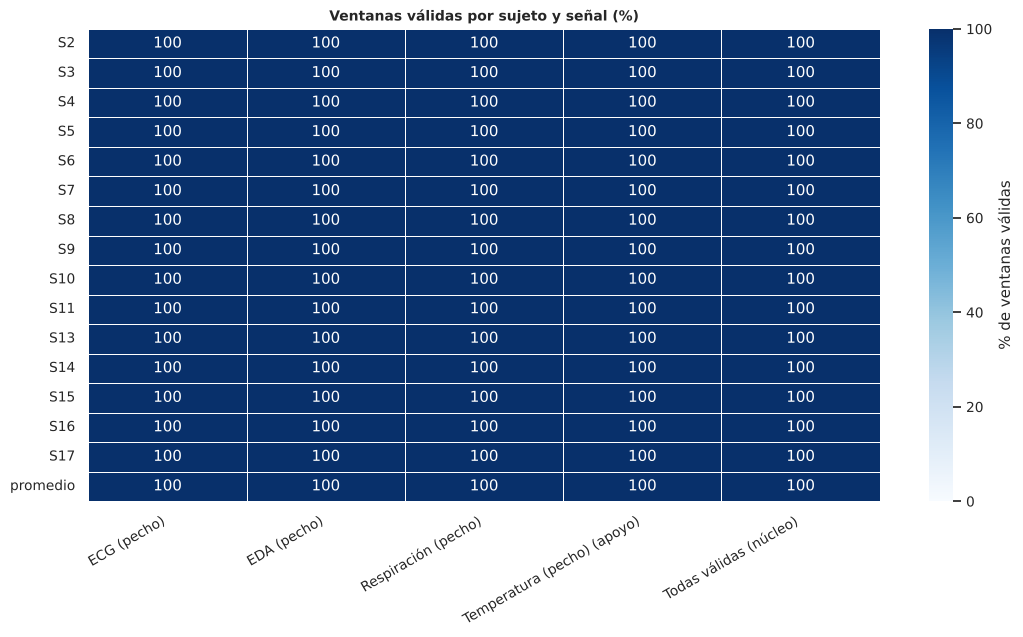

In [3]:
vcols = [f"valida__{k}" for k in cfg.EXPORT_SIGNALS]
ret = 100 * win.groupby("sujeto")[vcols + ["todas_validas"]].mean()
ret.columns = [cfg.SIGNALS[c.split("__")[1]]["name"] + (" (apoyo)" if c.split("__")[1] in cfg.SUPPORT_SIGNALS else "")
               if "__" in c else "Todas válidas (núcleo)" for c in ret.columns]
ret = ret.loc[sorted(ret.index, key=gr.subject_sort_key)]
ret.loc["promedio"] = ret.mean()
ret.to_csv(os.path.join(cfg.OUT_DIRS["tables"], "retencion_ventanas.csv"))
fig, ax = plt.subplots(figsize=(11, 6.5))
sns.heatmap(ret, annot=True, fmt=".0f", cmap="Blues", vmin=0, vmax=100, linewidths=0.5, linecolor="white",
            cbar_kws={"label": "% de ventanas válidas"}, ax=ax)
ax.set_title("Ventanas válidas por sujeto y señal (%)"); ax.set_ylabel(""); plt.xticks(rotation=30, ha="right")
fig.tight_layout(); gr.savefig(fig, "05_retencion_ventanas"); plt.show()

## 3. Balance de clases
Número de ventanas por clase en cada tarea, usando solo ventanas donde todas las señales son válidas.

In [4]:
ok = win[win.todas_validas]
bal = pd.DataFrame({
    "3 clases": ok.y_3clases.map({0: "Línea base", 1: "Estrés", 2: "Diversión"}).value_counts(),
    "binaria": ok.y_binaria.map({0: "No estrés", 1: "Estrés"}).value_counts(),
})
bal["% 3 clases"] = (100 * bal["3 clases"] / bal["3 clases"].sum()).round(1)
bal["% binaria"] = (100 * bal["binaria"] / bal["binaria"].sum()).round(1)
bal

,3 clases,binaria,% 3 clases,% binaria
Diversión,18714.0,NaN,15.4,NaN
Estrés,36279.0,36279.0,29.8,29.8
Línea base,66859.0,NaN,54.9,NaN
No estrés,NaN,85573.0,NaN,70.2


## 4. Normalización (se aplica en el objetivo 2, dentro de cada pliegue)
Las personas tienen niveles distintos (lo vimos en el notebook 04). Se dejan listas dos opciones en
`wesad_pre/ventanas.py`, y se comparan en el objetivo 2:

- **Opción A — `zscore_por_sujeto`** (Ben-Shakhar 1985; Nkurikiyeyezu et al. 2019 para la calibración personalizada): cada sujeto se normaliza con la media y
  desviación de **su propia línea base**. Supone que, al usar el sistema con una persona nueva, primero se graba un
  reposo corto de calibración. Suele dar mejores resultados.
- **Opción B — `ZScoreGlobal`**: la media y desviación se calculan **solo con los sujetos de entrenamiento** y se
  aplican tal cual al sujeto de prueba. Es el escenario más estricto (sin calibración).

Importante: la normalización se aplica a las **características** (objetivo 2), no a las señales, y siempre
**dentro de cada pliegue LOSO** para no filtrar información del sujeto de prueba.

Ejemplo de uso con una característica de juguete (el índice de movimiento), aplicado a **los 15 sujetos**.
Para la opción B se simula la validación LOSO: cada sujeto se normaliza con la media y desviación de los otros 14.
La tabla muestra, por condición, la mediana entre sujetos de cada versión.

In [5]:
col = ["movimiento__chest_ACC"]
demo = win[["sujeto", "condicion"] + col].copy()
a = ventanas.zscore_por_sujeto(demo, col)                       # opción A
b_partes = []
for sid in demo.sujeto.unique():                                 # opción B, un pliegue LOSO por sujeto
    train, test = demo[demo.sujeto != sid], demo[demo.sujeto == sid]
    b_partes.append(ventanas.ZScoreGlobal().fit(train, col).transform(test))
b = pd.concat(b_partes)

def mediana_por_condicion(df):
    return df.groupby(["sujeto", "condicion"])[col[0]].mean().groupby("condicion").median()

pd.DataFrame({"original (g)": mediana_por_condicion(demo),
              "opción A (z, línea base propia)": mediana_por_condicion(a),
              "opción B (z, otros 14 sujetos)": mediana_por_condicion(b)}).loc[cfg.COND_ORDER].round(3)

,original (g),"opción A (z, línea base propia)","opción B (z, otros 14 sujetos)"
condicion,,,
baseline,0.005,0.000,-0.359
stress,0.014,4.587,1.361
amusement,0.005,0.131,-0.341
meditation,0.004,-0.518,-0.507


## 5. Exportar

In [6]:
out = os.path.join(cfg.OUT_DIRS["tables"], "ventanas.csv.gz")
win.to_csv(out, index=False)
import json, shutil
with open(os.path.join("salidas", "config_usada.json"), "w", encoding="utf-8") as f:
    json.dump({k: getattr(cfg, k) for k in ["SUBJECT_IDS", "QC", "CLEAN", "MAX_GAP_INTERP_S", "EVENTS", "WINDOW", "TASKS"]},
              f, ensure_ascii=False, indent=2, default=str)
print("Guardado:", out, "y salidas/config_usada.json")

Guardado: salidas/tablas/ventanas.csv.gz y salidas/config_usada.json


## 📌 Qué encontramos con los datos reales
- **161 902 ventanas** en total (meditación incluida, sin etiqueta).
- **El 100 % de las ventanas es válido** para las 3 señales núcleo del modelo y para la temperatura de apoyo: el QC por muestra casi no excluye nada
  (notebook 02). La calidad que sí varía está en `ecg_frac_sqi_ok` (ECG), que el objetivo 2 puede usar para filtrar
  o como análisis de sensibilidad.
- **Balance:** 3 clases = 55 % línea base, 30 % estrés y 15 % diversión; binaria = 30 % estrés y 70 % no estrés.

## ¿Qué recibe el objetivo 2?
| Archivo | Contenido |
|---|---|
| `salidas/limpias/S{id}_procesado.pkl.gz` | señales limpias, máscaras de validez y eventos (picos R, SCL/SCR, respiraciones) |
| `salidas/tablas/ventanas.csv.gz` | el índice de ventanas con etiquetas y calidad por señal |
| `salidas/qc/S{id}_qc.npz` | máscaras del control de calidad de las 10 señales |
| `salidas/tablas/*.csv` | tablas del capítulo (QC, eventos, marcadores, pruebas, retención) |
| `salidas/config_usada.json` | todos los parámetros usados (reproducibilidad) |

Para extraer características: recorrer `ventanas.csv.gz`, abrir el `.pkl` del sujeto y calcular, para cada
ventana válida, las características de cada señal con los eventos que caen entre `inicio_s` y `fin_s`.